# Day 6

Tracing journey in Edinburgh in the style of the Marauder's Map

## 1. Imports
- osmnx downloads OpenStreetMap data.
- geopandas and shapely handle the geometry: buffering, unions, scaling, rotating and translating shapes.
- matplotlib renders the maps. Figure and FigureCanvasAgg are used later for off-screen GIF frames.
- PIL handles image work for the parchment and the GIF.
- folium, branca and jinja2 build the interactive route-drawing web map.

In [1]:
import os
import numpy as np
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from shapely.geometry import Point, LineString
from shapely.ops import unary_union
from shapely.affinity import scale as sscale, translate, rotate
from PIL import Image, ImageFilter
import folium
from folium.plugins import Draw, Fullscreen
from branca.element import MacroElement
from jinja2 import Template

## 2. Make the torn parchment for the background

Download a parchment background and name it background.png. Run the subsequent code to give it a more ragged, torn edge as the background

In [39]:
# load the image with an alpha channel so transparency can be set later
im = Image.open("background.png").convert("RGBA")
w, h = im.size
rng = np.random.default_rng(3) # random seed = 3

# function to create one wavy edge line
def wobble(n, amp):
    x = np.cumsum(rng.normal(0, 1, n)) # gives n random steps
    x = np.convolve(x, np.ones(25) / 25, mode="same") # removes pixel-level jitter so edge looks wavy instead of hairy
    return (x - x.mean()) / (x.std() + 1e-9) * amp

# each line gets a random draw so the sides do not mirror each other
m = np.zeros((h, w), dtype=np.uint8)
top, bot = wobble(w, 12) + 18, h - 18 + wobble(w, 12)
left, right = wobble(h, 12) + 18, w - 18 + wobble(h, 12)
# decide which pixels are "inside"
yy, xx = np.mgrid[0:h, 0:w]
m[(yy > top[xx]) & (yy < bot[xx]) & (xx > left[yy]) & (xx < right[yy])] = 255

# soften te edge and applies it
mask = Image.fromarray(m).filter(ImageFilter.GaussianBlur(1.5))
im.putalpha(mask)
im.save("background_torn.png")

## 3. Configurations

Set the configurations for the place of interest, size of buildings/paths and colours

In [55]:
# configuration (change to your own location, CRS, file name etc. and tinker with the parameters)
PLACE = "edinburgh"                             
CRS   = 27700                                   # British National Grid (metres)
BOUNDARY_FILE = "Edinburgh_Old_Town.geojson"    # single polygon, EPSG:4326
REFRESH = False                                 # set True once to re-download, then back to False

# street / building tuning (metres), exaggerated so the prints fit
SCALE, MIN_HALF_WIDTH = 1.2, 5       # sets how wide streets are carved
CORRIDOR = 11                        # sets how much room is cleared around the route
SHRINK, MIN_AREA = 1.0, 15           # control building clean-up
INK = "#5a4630"        # walls colour: mid brown
FOOT_INK = "#1f140a"   # footprints colour: near black
FOOT_ALPHA = 0.95
PARCHMENT_FILE = "background_torn.png"   # or None

RAW = f"{PLACE}_raw.gpkg"    # cache file name
LINES, POLYS = ["LineString", "MultiLineString"], ["Polygon", "MultiPolygon"]

## 4. Load the boundary

Read the boundary file and prepare the area for mapping

In [5]:
bnd = gpd.read_file(BOUNDARY_FILE)
if bnd.crs is None: # if no CRS, it assumes WGS84 then reprojects to metres
    bnd = bnd.set_crs(4326)
bnd = bnd.to_crs(CRS)
CLIP = unary_union(list(bnd.geometry)).buffer(0)            # one clean polygon (metres)
AREA_LL = gpd.GeoSeries([CLIP], crs=CRS).to_crs(4326).iloc[0]   # polygon in lat/lon for the OSM download
_c = gpd.GeoSeries([CLIP.centroid], crs=CRS).to_crs(4326).iloc[0]
CENTRE = (_c.y, _c.x)                                       # (lat, lon) for the drawing map
print("boundary area:", round(CLIP.area / 1e6, 2), "km2 | centre:", CENTRE) # prints the area and the centre coordinates

boundary area: 0.67 km2 | centre: (55.94853498392026, -3.192507483923771)


## 5. Download OSM data (with caching)

Fetches the map data

In [17]:
# download (cache)
def get(tags, kinds): # queries OSM features inside the boundary and keeps only the geometry type wanted
    try:
        g = ox.features_from_polygon(AREA_LL, tags)
    except Exception as e:
        print("no data for", tags, "-", e)
        return gpd.GeoDataFrame(geometry=[], crs=CRS) # reprojects the data to metres
    return g[g.geom_type.isin(kinds)].to_crs(CRS)

def save_raw(gdf, layer, keep=()): # writes seleted columns and convert to strings as a layer in GeoPackage to avoid errors from OSM's mixed-type columns
    if len(gdf):
        cols = [c for c in keep if c in gdf.columns]
        out = gdf[cols + ["geometry"]].copy()
        for c in cols:
            out[c] = out[c].astype(str)
        out.to_file(RAW, layer=layer, driver="GPKG")

def load_raw(layer): # reads a layer back from the GeoPackage
    try:
        return gpd.read_file(RAW, layer=layer)
    except Exception:
        return gpd.GeoDataFrame(geometry=[], crs=CRS)

# the download only runs if the cache file doesn't exist. Fetches the streets, buildings and green layer
if REFRESH and os.path.exists(RAW):
    os.remove(RAW)

if not os.path.exists(RAW):
    save_raw(get({"highway": True}, LINES), "streets", keep=("highway",))
    save_raw(get({"building": True}, POLYS), "buildings")
    save_raw(get({"leisure": ["park", "garden"], "landuse": "grass"}, POLYS), "green")

streets   = load_raw("streets")
buildings = load_raw("buildings")
green     = load_raw("green")

## 6. Clip to the boundary

Trims all the layers to the boundary of interest and prints number of features

In [19]:
# clip to the boundary
if len(streets):
    streets = gpd.clip(streets, CLIP)
    streets = streets[streets.geom_type.isin(LINES)]
if len(buildings):
    buildings = buildings[buildings.centroid.within(CLIP)]
if len(green):
    green = gpd.clip(green, CLIP)
    green = green[green.geom_type.isin(POLYS)]
print(len(streets), "street lines |", len(buildings), "buildings |", len(green), "green areas")

1334 street lines | 823 buildings | 146 green areas


## 7. Build the basemap

Turns the buildings into the map's walls

In [21]:
# build the basemap
widths = {"primary": 14, "secondary": 12, "tertiary": 10, "residential": 8,
          "pedestrian": 8, "service": 5, "footway": 4, "path": 4, "steps": 4}
def half_w(h):
    return max(widths.get(h, 5) * SCALE, MIN_HALF_WIDTH)

def build_base(track=None):
    geoms = []
    # streets are buffered based on its type. Widths are exaggered to ensure footprints can fit.
    if len(streets):
        geoms = [g.buffer(half_w(h)) for g, h in zip(streets.geometry, streets["highway"])]
    if track is not None:
        geoms.append(track.buffer(CORRIDOR))          # guaranteed room for the prints
    street_area = unary_union(geoms)

    # tidy buildings are dropped and the rest are merged together
    b = buildings[buildings.area > MIN_AREA]
    blocks = unary_union(list(b.geometry.buffer(0.5))).buffer(-0.5).buffer(-SHRINK)
    blocks = blocks.difference(street_area).simplify(0.8)
    blocks = blocks.intersection(CLIP)                # trim walls at the boundary edge

    # merged shape is exploded into indvidual polygons and empty or invalid pieces are moved
    outer = gpd.GeoDataFrame(geometry=[blocks], crs=CRS).explode(index_parts=False)
    outer = outer[~outer.is_empty & outer.is_valid].reset_index(drop=True)

    # each block is copied and inset by 1.2 m. This gives the double-line wall effect of the Marauder’s Map.
    # blocks smaller than 40 m² are skipped so tiny buildings don’t become smudges.
    inner = outer.copy()
    inner["geometry"] = outer.buffer(-1.2)
    inner = inner[~inner.is_empty]
    inner = inner[outer.loc[inner.index].area > 40]   # skip inner lines on tiny buildings
    return blocks, street_area, outer, inner

blocks, street_area, outer, inner = build_base(None)

## 8. Fixed extent and rendering helpers

Sets up how every image is drawn

In [61]:
# fix the map bounds and a 16-inch-wide figure whose aspect ratio matches the boundary, so every export lines up exactly
minx, miny, maxx, maxy = CLIP.bounds
xlim, ylim = (minx, maxx), (miny, maxy)
w_in = 16
h_in = w_in * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

# draws thick outer walls, thin faint inner walls and dashed outlines for green area
def draw_base(ax):
    outer.plot(ax=ax, facecolor="none", edgecolor=INK, linewidth=1.1, alpha=0.8)
    inner.plot(ax=ax, facecolor="none", edgecolor=INK, linewidth=0.35, alpha=0.6)
    if len(green):
        green.plot(ax=ax, facecolor="none", edgecolor=INK, linewidth=0.6,
                   linestyle="--", alpha=0.5)

def _parchment_cover(path, aspect):
    # crops the image to the map's aspect ratio, so it is never stretched
    im = Image.open(path).convert("RGB")
    w, h = im.size
    if w / h > aspect:
        nw = int(h * aspect); x0 = (w - nw) // 2
        im = im.crop((x0, 0, x0 + nw, h))
    else:
        nh = int(w / aspect); y0 = (h - nh) // 2
        im = im.crop((0, y0, w, y0 + nh))
    return np.asarray(im)

# export function
def render(name, base=True, feet=None, guide=None, dpi=300, parchment=False):
    use_bg = parchment and PARCHMENT_FILE and os.path.exists(PARCHMENT_FILE)
    fig = plt.figure(figsize=(w_in, h_in))
    ax = fig.add_axes([0, 0, 1, 1])
    # uses the parchment as the background or a transparent canvas
    if use_bg:
        ax.imshow(_parchment_cover(PARCHMENT_FILE, w_in / h_in),
                  extent=(*xlim, *ylim), aspect="auto", zorder=0)
    else:
        fig.patch.set_alpha(0); ax.patch.set_alpha(0)
    if base:
        draw_base(ax)
    if feet is not None and len(feet):
        feet.plot(ax=ax, facecolor=FOOT_INK, edgecolor="none", alpha=FOOT_ALPHA)
    if guide is not None:
        gpd.GeoSeries([guide], crs=CRS).plot(ax=ax, color="red", linewidth=1)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect("equal"); ax.set_axis_off()
    fig.savefig(f"{name}.png", dpi=dpi, transparent=not use_bg)
    if not use_bg:
        fig.savefig(f"{name}.svg", transparent=True)   # no SVG for the parchment version
    plt.close(fig)

## 9. Quick preview

Provides an image of base map for quick preview

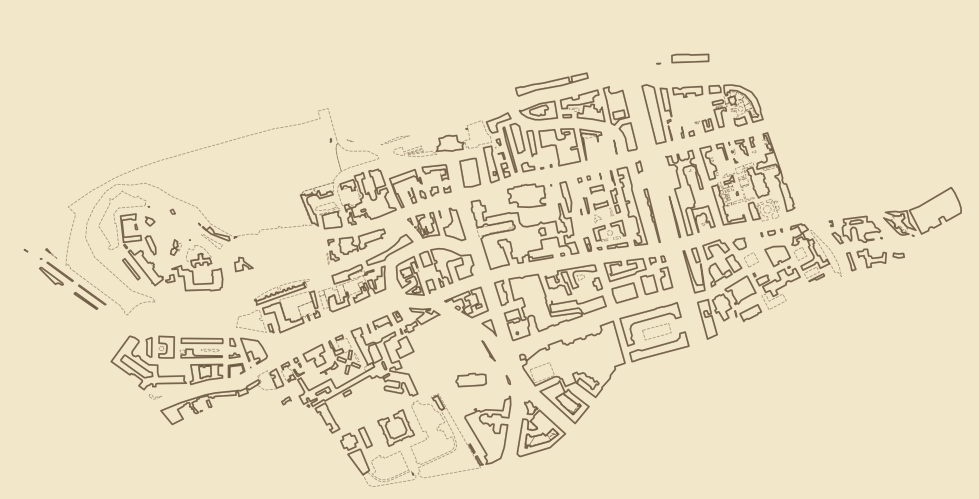

In [63]:
# quick preview for visualisation
fig = plt.figure(figsize=(w_in * 0.6, h_in * 0.6))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_facecolor("#f3e7c9"); fig.patch.set_facecolor("#f3e7c9")
draw_base(ax)
ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect("equal"); ax.set_axis_off()
plt.show()

render(f"{PLACE}_base_preview", base=True)   # transparent export, map only

## 10. Interactive route-drawing map

This cell builds draw_route.html, a web page where you digitise your route by hand. Do not proceed to Step 11 until this is done

In [36]:
def ll(g): return g.to_crs(4326)

m = folium.Map(location=CENTRE, zoom_start=16, max_zoom=21, tiles=None)

# basemaps for background
def basemap(name, url, attr, show=False):
    folium.TileLayer(tiles=url, attr=attr, name=name, show=show,
                     max_native_zoom=19, max_zoom=21).add_to(m)

basemap("Streets (Esri)",
        "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        "Esri World Street Map", show=True)
basemap("Satellite (Esri)",
        "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        "Esri World Imagery")

# reference overlays where street corridors are blue, walls are red and boundary orange to show where footprints will fit
sty = lambda col, w, fill=False: (lambda f: {"color": col, "weight": w, "fill": fill, "fillOpacity": 0.25})

folium.GeoJson(ll(gpd.GeoDataFrame(geometry=[street_area], crs=CRS))[["geometry"]],
               name="corridors", style_function=sty("#1f78b4", 0.3, True)).add_to(m)
folium.GeoJson(ll(outer)[["geometry"]],
               name="my walls", style_function=sty("#b3261e", 1.0)).add_to(m)
folium.GeoJson(ll(gpd.GeoDataFrame(geometry=[CLIP], crs=CRS))[["geometry"]],
               name="boundary", style_function=sty("#ff9800", 2)).add_to(m)

# create a drawing tool restricted to polylines only
Draw(export=False,
     draw_options={"polyline": {"shapeOptions": {"color": "yellow", "weight": 4}},
                   "polygon": False, "rectangle": False, "circle": False,
                   "marker": False, "circlemarker": False}).add_to(m)

# custom MacroElement to collect every line drawn, remove lines deleted and adds a save route button
class SaveButton(MacroElement):
    _template = Template("""
    {% macro script(this, kwargs) %}
    var map_ = {{ this._parent.get_name() }};
    var drawn = new L.FeatureGroup().addTo(map_);
    map_.on('draw:created', function(e){ drawn.addLayer(e.layer); });
    map_.on('draw:deleted', function(e){
        e.layers.eachLayer(function(l){ drawn.removeLayer(l); });
    });
    var Btn = L.Control.extend({
      options: {position: 'bottomleft'},
      onAdd: function(){
        var b = L.DomUtil.create('button');
        b.innerHTML = 'Save route.geojson';
        b.style.cssText = 'padding:10px 14px;font-size:14px;background:#fff;' +
                          'border:2px solid #333;border-radius:4px;cursor:pointer;';
        L.DomEvent.disableClickPropagation(b);
        b.onclick = function(){
          var data = drawn.toGeoJSON();
          if (!data.features.length){ alert('Draw a line first'); return; }
          var blob = new Blob([JSON.stringify(data)], {type: 'application/json'});
          var a = document.createElement('a');
          a.href = URL.createObjectURL(blob);
          a.download = 'route.geojson';
          a.click();
        };
        return b;
      }
    });
    map_.addControl(new Btn());
    {% endmacro %}
    """)

m.add_child(SaveButton())

# a lat/lon popup on click, a fullscreen button and a layer switcher
folium.LatLngPopup().add_to(m)
Fullscreen().add_to(m)
folium.LayerControl(collapsed=True).add_to(m)

m.save("draw_route.html")
print("Open draw_route.html in Chrome or Edge")

Open draw_route.html in Chrome or Edge


## 11. Create static maps with the footprints

In [75]:
# footprint settings (ground metres)
STEP, OFFSET, PRINT_LEN = 42.0, 6.0, 28.0
CORRIDOR = 11
CLEARANCE = 1.0    # min gap between a print and a wall (m)
MIN_GAP   = 2.0    # min gap between two prints (m)
JITTER_ANGLE, JITTER_POS = 5, 0.4
ROUTE_FILE = "route.geojson"

if not os.path.exists(ROUTE_FILE):
    raise SystemExit("Draw your route in draw_route.html and save route.geojson here.")

# load the routem joins all drawn segments into one line and simplifies it
r = gpd.read_file(ROUTE_FILE).to_crs(CRS)
coords = []
for ln in r.geometry.explode(index_parts=False):
    if ln.geom_type == "LineString":
        coords += list(ln.coords)
track = LineString(coords).simplify(0.5)
print("route length:", round(track.length), "m")

# # rebuild the map
blocks, street_area, outer, inner = build_base(track)

# adjust footprint size and movement around the route
rng = np.random.default_rng(7)
def ell(cx, cy, a, b):
    return translate(sscale(Point(0, 0).buffer(1, 32), a, b), cx, cy)
def sole(L):
    # toe points +y, total length = L
    fore = ell(0.0, 0.66 * L, 0.115 * L, 0.29 * L)       # forefoot: narrow and long
    fore = rotate(fore, -6, origin=(0, 0.45 * L))        # slight outward lean
    heel = ell(0.0, 0.15 * L, 0.08 * L, 0.125 * L)       # heel, with a gap above it
    return unary_union([fore, heel])

base_sole = sole(PRINT_LEN)
keep = blocks.buffer(CLEARANCE)
rows, placed = [], []
for i, d in enumerate(np.arange(STEP / 2, track.length - 1, STEP)):
    p1, p2 = track.interpolate(d), track.interpolate(d + 1.0)
    ang = np.arctan2(p2.y - p1.y, p2.x - p1.x)
    side = 1 if i % 2 == 0 else -1
    deg = np.degrees(ang) - 90 + rng.normal(0, JITTER_ANGLE)
    jx, jy = rng.normal(0, JITTER_POS), rng.normal(0, JITTER_POS)
    s0 = base_sole if side == 1 else sscale(base_sole, -1, 1, origin=(0, 0))
    s0 = rotate(s0, deg, origin=(0, 0))

    for f in (1.0, 0.7, 0.4, 0.0):               # try full offset, then move toward the route line
        x = p1.x + side * OFFSET * f * np.cos(ang + np.pi / 2) + jx
        y = p1.y + side * OFFSET * f * np.sin(ang + np.pi / 2) + jy
        s = translate(s0, x, y)
        if s.intersects(keep):
            continue
        if any(s.distance(p) < MIN_GAP for p in placed):
            continue
        placed.append(s)
        rows.append({"geometry": s, "side": side, "i": i, "t": d / track.length})
        break

feet = gpd.GeoDataFrame(rows, crs=CRS)
print(len(feet), "footprints")

# save and export
out = f"{PLACE}.gpkg"
outer.to_file(out, layer="walls_outer", driver="GPKG")
inner.to_file(out, layer="walls_inner", driver="GPKG")
feet.to_file(out, layer="footprints", driver="GPKG")
gpd.GeoDataFrame(geometry=[track], crs=CRS).to_file(out, layer="track", driver="GPKG")

# five images are rendered
render(f"{PLACE}_base",       base=True,  feet=None) 
render(f"{PLACE}_footprints", base=False, feet=feet)
render(f"{PLACE}_full",       base=True,  feet=feet) 
render(f"{PLACE}_guide",      base=True,  feet=None, guide=track)
render(f"{PLACE}_full_parchment", base=True, feet=feet, parchment=True)
print("done")

route length: 2921 m
63 footprints
done


In [19]:
## 12. Create GIF map

In [ ]:
# settings
OUT_GIF        = f"{PLACE}_walk.gif"
PARCHMENT_FILE = "background_torn.png"
BG_COLOUR      = "#161b22"    # shows through the torn edges, so match the page you post it on
MARGIN         = 1.12         # parchment around the map (1.0 = map fills the frame)
PX_WIDTH       = 1000
PRINTS_PER_FRAME = 1
FRAME_MS       = 180
HOLD_START, HOLD_END = 8, 30
FADE = 3
MAX_ALPHA      = FOOT_ALPHA   # from Cell 1

In [77]:
bg = None
if PARCHMENT_FILE and os.path.exists(PARCHMENT_FILE): # load the torn parchment with transparency
    bg = Image.open(PARCHMENT_FILE).convert("RGBA")    # keeps the torn edge transparency
    pa = bg.width / bg.height
    cx, cy = (xlim[0] + xlim[1]) / 2, (ylim[0] + ylim[1]) / 2
    mw, mh = (xlim[1] - xlim[0]) * MARGIN, (ylim[1] - ylim[0]) * MARGIN
    gw, gh = (mw, mw / pa) if mw / mh > pa else (mh * pa, mh)
    gxlim, gylim = (cx - gw / 2, cx + gw / 2), (cy - gh / 2, cy + gh / 2)
    fig_w, fig_h = w_in, w_in / pa
else:
    gxlim, gylim, fig_w, fig_h = xlim, ylim, w_in, h_in

# set up a hidden drawing Canvas
fig = Figure(figsize=(fig_w, fig_h), dpi=PX_WIDTH / fig_w)
canvas = FigureCanvasAgg(fig)
ax = fig.add_axes([0, 0, 1, 1])
fig.patch.set_facecolor(BG_COLOUR)
ax.set_facecolor(BG_COLOUR)

if bg is not None:
    ax.imshow(np.asarray(bg), extent=(*gxlim, *gylim), aspect="auto", zorder=0)

draw_base(ax)
ax.set_xlim(*gxlim); ax.set_ylim(*gylim); ax.set_aspect("equal"); ax.set_axis_off()
n_base = len(ax.collections)          # everything after this is footprints

feet_sorted = feet.sort_values("i").reset_index(drop=True)
N = len(feet_sorted)

def grab():
    canvas.draw()
    return Image.fromarray(np.asarray(canvas.buffer_rgba())).convert("RGB")

def to_gif_frame(im):
    return im.convert("P", palette=Image.ADAPTIVE, colors=256)

# Build the frames
frames = []
empty = to_gif_frame(grab())
frames += [empty] * HOLD_START

for n in list(range(PRINTS_PER_FRAME, N, PRINTS_PER_FRAME)) + [N]:
    for c in list(ax.collections)[n_base:]:
        c.remove()
    solid = feet_sorted.iloc[:max(n - FADE, 0)]
    if len(solid):
        solid.plot(ax=ax, facecolor=FOOT_INK, edgecolor="none", alpha=MAX_ALPHA)
    for k in range(FADE):
        idx = n - FADE + k
        if 0 <= idx < N:
            feet_sorted.iloc[[idx]].plot(ax=ax, facecolor=FOOT_INK, edgecolor="none",
                                         alpha=MAX_ALPHA * (k + 1) / (FADE + 1))
    frames.append(to_gif_frame(grab()))

frames += [frames[-1]] * HOLD_END

frames[0].save(OUT_GIF, save_all=True, append_images=frames[1:],
               duration=FRAME_MS, loop=0, optimize=False)
print(f"{len(frames)} frames, ~{len(frames) * FRAME_MS / 1000:.1f} s -> {OUT_GIF}")

101 frames, ~18.2 s -> edinburgh_walk.gif


<Figure size 640x480 with 0 Axes>